# Projeto de Fusão de Informação em Análises de Dados

<div style="width: 100%; overflow: hidden;">

    <a href="http://www.uc.pt/fctuc/dei/">

    <div style="display: block;margin-left: auto;margin-right: auto; width: 100%;"><img src="https://eden.dei.uc.pt/~naml/images_ecos/dei25.png"  /></div>

    </a>

</div>

---

#### Afonso Rodrigues -- 2020242400
#### Emanuel Pacheco -- 2024138898


In [297]:
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as Rot
import scipy.linalg
from IPython.display import display, clear_output

In [298]:
# Estimation parameters of EKF and UKF
Q = np.diag([0.1, 0.1, np.deg2rad(1.0), 1.0]) ** 2  # predict state covariance
R = np.diag([1.0, 1.0]) ** 2  # Observation x,y position covariance

#  Simulation parameter
GPS_Noise = np.diag([0.5, 0.5])**2
Input_Noise = np.diag([1.0, np.deg2rad(30.0)])**2

#  UKF Parameters
ALPHA = 0.001
BETA = 2
KAPPA = 0

dt = 0.1  # time tick [s]
SIM_TIME = 50.0 # finish simulation

In [299]:
def calc_input():
    v = 1.0  # [m/s]
    yawrate = 0.1  # [rad/s]
    u = np.array([[v, yawrate]]).T
    return u

In [300]:
def motion_model(x, u):
    yaw = x[2, 0]  # Current yaw

    # State transition matrix
    A = np.array([[1, 0, 0, 0],
                  [0, 1, 0, 0],
                  [0, 0, 1, 0],
                  [0, 0, 0, 0]])

    # Control input matrix
    B = np.array([[np.cos(yaw) * dt, 0],
                  [np.sin(yaw) * dt, 0],
                  [0, dt],
                  [1, 0]])

    # State update
    x = A.dot(x) + B.dot(u)

    return x

In [301]:
def observation(xTrue, xd, u):
    xTrue = motion_model(xTrue, u)

    # Add noise to GPS x-y
    zx = xTrue[0, 0] + np.random.randn() * GPS_Noise[0, 0]
    zy = xTrue[1, 0] + np.random.randn() * GPS_Noise[1, 1]
    z = np.array([[zx, zy]])

    # Add noise to input
    ud1 = u[0, 0] + np.random.randn() * Input_Noise[0, 0]
    ud2 = u[1, 0] + np.random.randn() * Input_Noise[1, 1]
    ud = np.array([[ud1, ud2]]).T

    xd = motion_model(xd, ud)

    return xTrue, z, xd, ud

In [302]:
def observation_model(x):
    # Observation matrix (maps state to measurement)
    C = np.array([[1, 0, 0, 0],
                  [0, 1, 0, 0]])

    z = C.dot(x)

    return z

In [303]:
def plot_covariance_ellipse(xEst, PEst):
    Pxy = PEst[0:2, 0:2]
    eigval, eigvec = np.linalg.eig(Pxy)

    if eigval[0] >= eigval[1]:
        bigind = 0
        smallind = 1
    else:
        bigind = 1
        smallind = 0

    t = np.arange(0, 2 * math.pi + 0.1, 0.1)
    a = math.sqrt(eigval[bigind])
    b = math.sqrt(eigval[smallind])
    x = [a * math.cos(it) for it in t]
    y = [b * math.sin(it) for it in t]
    angle = math.atan2(eigvec[bigind, 1], eigvec[bigind, 0])
    R = np.array([[math.cos(angle), math.sin(angle)],
                  [-math.sin(angle), math.cos(angle)]])
    fx = R.dot(np.array([[x, y]]))
    px = np.array(fx[0, :] + xEst[0, 0]).flatten()
    py = np.array(fx[1, :] + xEst[1, 0]).flatten()
    plt.plot(px, py, "--r")

##  EKF

In [304]:
def jacobF(x, u):
    v = u[0, 0] 
    yaw = x[2, 0]

    # Jacobian of Motion Model
    jF = np.array([[1, 0, -v * np.sin(yaw) * dt, np.cos(yaw) * dt],
                   [0, 1,  v * np.cos(yaw) * dt, np.sin(yaw) * dt],
                   [0, 0, 1, 0],
                   [0, 0, 0, 1]])

    return jF

In [305]:
def jacobH(x):
    # Jacobian of Observation Model
    jH = np.array([[1, 0, 0, 0],
                   [0, 1, 0, 0]])

    return jH

In [306]:
def ekf_estimation(xEst, PEst, z, u):
    #  Predict
    #  State Extrapolation
    xPred = motion_model(xEst, u)
    
    #  Covariance Extrapolation
    jF = jacobF(xEst, u)
    PPred = jF.dot(PEst).dot(jF.T) + Q
    

    #  Update
    #  Kalman Gain
    jH = jacobH(xPred)
    K = PPred.dot(jH.T).dot(np.linalg.inv(jH.dot(PPred).dot(jH.T) + R))

    #  State Update
    xEst = xPred + K.dot(z.T - observation_model(xPred))

    #  Covariance Update
    PEst = (np.eye(len(xEst)) - K.dot(jH)).dot(PPred)
    
    return xEst, PEst

## UKF

In [307]:
def generate_sigma_points(xEst, PEst, gamma):
    # Calculate the sigma points using xEst (xhat_k|k), PEst (P_k|k) and gamma
    # or using xPred (xhat_k|k-1), PPred (P_k|k-1) and gamma
    x_0 = xEst

    sigma_neg = xEst + gamma * scipy.linalg.sqrtm(PEst)
    sigma_pos = xEst - gamma * scipy.linalg.sqrtm(PEst)

    sigma = np.concatenate((x_0, sigma_neg, sigma_pos), axis=1)

    return sigma

In [308]:
def predict_sigma_motion(sigma, u):
    # Sigma Points prediction with motion model
    sigma = motion_model(sigma, u)
    return sigma

In [309]:
def predict_sigma_observation(sigma):
    # Sigma Points prediction with observation model
    sigma = observation_model(sigma)
    return sigma

In [310]:
def calc_sigma_covariance(x, sigma, wc, Pi):
    # Calculate the covariance P = PPred (P_k|k-1) using x = xPred (xhat_k+1|k),
    # sigma (x^(i)_k+1|k), wc and Pi = Q (initial value of PPred)
    # or calculate the covariance P = st (P^yy_t|t-1) using x = zb (yhat_t),
    # sigma = z_sigma (y^(i)_t), wc and Pi = R (initial value of st)
    P = (wc * (sigma - x)).dot((sigma - x).T) + Pi

    return P

In [311]:
def calc_pxz(sigma, x, z_sigma, zb, wc):
    # Calculate the covariance Pxz (P^xy_t|t-1) using wc, sigma (x^(i)_t|t-1),
    # x (xhat_t|t-1), z_sigma (y^(i)_t) and zb (yhat_t) and 
    P = (wc * (sigma - x)).dot((z_sigma - zb).T)
    return P

In [312]:
def ukf_estimation(xEst, PEst, z, u, wm, wc, gamma):
    #  Predict (UKF - time update)
    
    # Calculate the sigma-points using xExt (xhat_k|k) and PEst (P_k|k)
    # and gamma in def generate_sigma_points
    sigma = generate_sigma_points(xEst, PEst, gamma)
    
    # Propagate the sigma-points (x^(i)_k+1|k = f(x^(i)_k|k , w^(i)_k)) 
    # using the sigma-points obtained in the previous calculus and u (ud = noisy u)
    # in def predict_sigma_motion
    sigma = predict_sigma_motion(sigma, u)

    # Calculate xPred (xhat_k+1|k) using wm and the propagated sigma-points 
    xPred = wm.dot(sigma.T).T

    # Calculate PPred (P_k|k-1) using xPred, the propagated sigma-points
    # wc and Q in def calc_sigma_covariance
    PPred = calc_sigma_covariance(xPred, sigma, wc, Q)
    
    #  Update (UKF - measurement update)
    
    # Calculate zPred (yhat_t) using xPred (xhat_k+1|k) in def observation_model
    zPred = observation_model(xPred)
    
    # Calculate y = (y_t - yhat_t) using z (y_t) and zPred (yhat_t)
    y = z.T - zPred
    
    # Calculate the sigma-points using xPred (xhat_k|k-1), PPred (P_k|k-1)
    # and gamma in def generate_sigma_points
    z_sigma = generate_sigma_points(xPred, PPred, gamma)

    # Propagate the sigma-points z_sigma (y^(i)_t = h(x^(i)_t|t-1 , e^(i)_t)) 
    # using the propagated sigma-points in def predict_sigma_observation
    z_sigma = predict_sigma_observation(z_sigma)
    
    # Calculate zb (yhat_t) using wm and the sigma-points y^(i)_t 
    zb = wm.dot(z_sigma.T).T
    
    # Calculate the sigma covariance, st (P^yy_t|t-1), using zb (yhat_t),
    # z_sigma (y^(i)_t), wc and R in def calc_sigma_covariance
    Pz = calc_sigma_covariance(zb, z_sigma, wc, R)
    
    # Calculate Pxz (P^xy_t|t-1) using sigma (x^(i)_t|t-1), xPred (xhat_t|t-1),
    # z_sigma (y^(i)_t), zb (yhat_t) and wc in def calc_pxz
    Pxz = calc_pxz(sigma, xPred, z_sigma, zb, wc)
    
    # Calculate K_t using Pxz (P^xy_t|t-1) and st (P^yy_t|t-1)
    K = Pxz.dot(scipy.linalg.inv(Pz))
    
    # Update xEst (Xhat_t|t) using xPred (xhat_t|t-1), K_t and y (y_t - yhat_t)
    xEst = xPred + K.dot(y)
    
    # Update PEst (P_t|t) using PPred (P_t|t-1), K_t and st (P^yy_t|t-1)
    PEst = PPred - K.dot(Pz).dot(K.T)
    
    return xEst, PEst

In [313]:
def setup_ukf(nx):
    # calculate lambda
    lamb = ALPHA ** 2 * (nx + KAPPA) - nx

    # calculate the weights
    # w^(0)
    wm = [lamb / (lamb + nx)] # wm corresponds to w of the UKF Algorithm
    # wc^(0)
    wc = [(lamb / (lamb + nx)) + (1 - ALPHA ** 2 + BETA)]
    for i in range(2 * nx):
        # w^(+-i)
        wm.append(1.0 / (2 * (nx + lamb)))
        # wc^(+-i)
        wc.append(1.0 / (2 * (nx + lamb)))
    
    # define gamma
    gamma = math.sqrt(nx + lamb)

    wm = np.array([wm])
    wc = np.array([wc])

    return wm, wc, gamma

## Main

In [314]:
def grafico(hxTrue, hxDR, hxEst, xEst, PEst, hz, fig, show_animation):
    if show_animation:
        plt.cla()
        plt.plot(hz[:, 0], hz[:, 1], ".g", label="Observation")
        plt.plot(hxTrue[0, :].flatten(),
                hxTrue[1, :].flatten(), "-b", label="True Position")
        plt.plot(hxDR[0, :].flatten(),
                hxDR[1, :].flatten(), "-k", label="Dead Reckoning")
        plt.plot(hxEst[0, :].flatten(),
                hxEst[1, :].flatten(), "-r", label="UKF")
        plot_covariance_ellipse(xEst, PEst)
        plt.axis("equal")
        plt.grid(True)

        clear_output(wait = True)
        display(fig)
    else:
        plt.plot(hz[:, 0], hz[:, 1], ".g", label="Observation")
        plt.plot(hxTrue[0, :].flatten(),
                hxTrue[1, :].flatten(), "-b", label="True Position")
        plt.plot(hxDR[0, :].flatten(),
                hxDR[1, :].flatten(), "-k", label="Dead Reckoning")
        plt.plot(hxEst[0, :].flatten(),
                hxEst[1, :].flatten(), "-r", label="UKF")
        plot_covariance_ellipse(xEst, PEst)
        plt.axis("equal")
        plt.grid(True)
        plt.show()

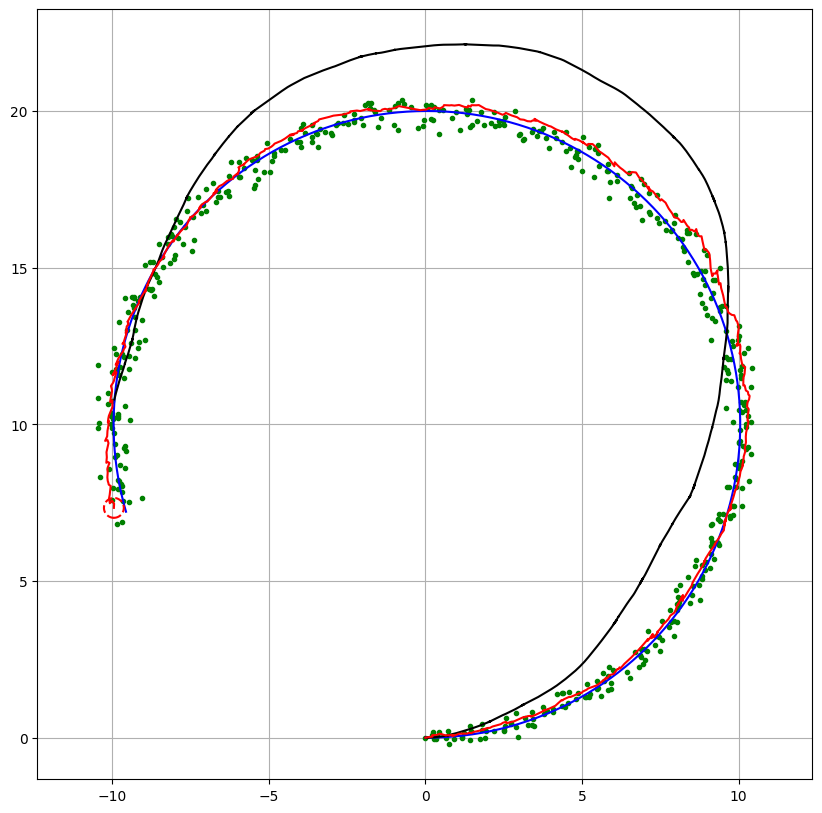

In [315]:
def ukf_or_ekf(algorithm, show_animation): # algorithm = UKF or algorithm = EKF
    print("Robot simulation start!")

    nx = 4  # State Vector [x y yaw v]'

    xEst = np.zeros((nx, 1))
    xTrue = np.zeros((nx, 1))
    PEst = np.eye(nx)

    if algorithm == "UKF":
        wm, wc, gamma = setup_ukf(nx)

    xDR = np.zeros((nx, 1))  # Dead reckoning

    # history
    hxEst = xEst
    hxTrue = xTrue
    hxDR = xTrue
    hz = np.zeros((1, 2))
    
    time = 0.0

    fig = plt.figure(figsize=(10, 10))
    
    while SIM_TIME > time:
        time += dt
        # effective values of the input variables (v and omega)
        u = calc_input()
        
        # xTrue: x_k|k-1 (given by the motion_model using x and u)
        # z: noisy GPS output variables (given by observation_model)
        # xDR: xDR_k|k-1 (given by the motion_model using xDR_k-1 and noisy u)
        # ud: noisy u
        xTrue, z, xDR, ud = observation(xTrue, xDR, u)

        # Estimation of xEst, PEst using the UKF algorithm 
        if algorithm == "UKF":
            xEst, PEst = ukf_estimation(xEst, PEst, z, ud, wm, wc, gamma)
        elif algorithm == "EKF":
            xEst, PEst = ekf_estimation(xEst, PEst, z, ud)

        # store data history
        hxEst = np.hstack((hxEst, xEst))
        hxDR = np.hstack((hxDR, xDR))
        hxTrue = np.hstack((hxTrue, xTrue))
        hz = np.vstack((hz, z))

        if show_animation:
            grafico(hxTrue, hxDR, hxEst, xEst, PEst, hz, fig, show_animation)     
            

    if show_animation:
        plt.close()

    else:
        grafico(hxTrue, hxDR, hxEst, xEst, PEst, hz, fig, show_animation)
        

ukf_or_ekf("UKF", True)